In [1]:
import pandas as pd

In [17]:
df_tones = pd.read_csv("mesure_8m_los_37_channel.csv")
df_procedure = pd.read_csv("mesure_8m_los_37_channel_procedures.csv")

In [18]:
df_tones.nunique()

host_time          1253
timestamp_ms         40
ranging_counter      40
ap                    1
channel              37
freq_mhz             37
h_re               1239
h_im               1239
amplitude          1252
phase_deg          1219
n_iqs                15
dtype: int64

In [10]:
df_procedure.head()

,host_time,timestamp_ms,ranging_counter,ap,tone_quality,rtt_count,rtt_mean_ns,tof_ns,rssi_dbm,dist_ifft_m,dist_phase_slope_m,dist_rtt_m
0,2026-11-03T12:10:03.640,21711,90,0,OK,22,93.27,46.64,-61.6,9.076,12.919,13.981
1,2026-11-03T12:10:04.140,22211,95,0,OK,21,90.64,45.32,-59.9,9.076,12.563,13.587
2,2026-11-03T12:10:04.640,22711,100,0,OK,19,78.55,39.28,-60.3,9.076,12.737,11.775
3,2026-11-03T12:10:05.140,23211,105,0,OK,22,99.57,49.78,-60.5,9.369,11.978,14.925
4,2026-11-03T12:10:05.639,23711,110,0,OK,17,78.18,39.09,-59.8,8.490,11.961,11.718


In [11]:
df = df_tones.merge(df_procedure, how="inner", on="ranging_counter")
df.head()

,host_time_x,timestamp_ms_x,ranging_counter,ap_x,channel,freq_mhz,h_re,h_im,amplitude,phase_deg,...,timestamp_ms_y,ap_y,tone_quality,rtt_count,rtt_mean_ns,tof_ns,rssi_dbm,dist_ifft_m,dist_phase_slope_m,dist_rtt_m
0,2026-11-03T12:10:03.242,21211,85,0,21,2423,12544.0,-17571.0,21589.1641,-54.48,...,35542,0,OK,18,83.42,41.71,-55.5,9.369,11.103,12.504
1,2026-11-03T12:10:03.248,21211,85,0,22,2424,2845.0,-17200.0,17433.7031,-80.61,...,35542,0,OK,18,83.42,41.71,-55.5,9.369,11.103,12.504
2,2026-11-03T12:10:03.253,21211,85,0,26,2428,-1407.0,-2481.0,2852.1938,-119.56,...,35542,0,OK,18,83.42,41.71,-55.5,9.369,11.103,12.504
3,2026-11-03T12:10:03.259,21211,85,0,27,2429,241.0,-5057.0,5062.7393,-87.27,...,35542,0,OK,18,83.42,41.71,-55.5,9.369,11.103,12.504
4,2026-11-03T12:10:03.265,21211,85,0,28,2430,-242.0,-10406.0,10408.8135,-91.33,...,35542,0,OK,18,83.42,41.71,-55.5,9.369,11.103,12.504


In [12]:
GROUND_TRUTH_DISTANCE = 8.0
import numpy as np

df["dist_ifft_mean_error_m"] = np.abs(GROUND_TRUTH_DISTANCE - df["dist_ifft_m"])
df["dist_phase_slope_mean_error_m"] = np.abs(GROUND_TRUTH_DISTANCE - df["dist_phase_slope_m"])
df["dist_rtt_mean_error_m"] = np.abs(GROUND_TRUTH_DISTANCE - df["dist_rtt_m"])

In [13]:
df.describe()

,timestamp_ms_x,ranging_counter,ap_x,channel,freq_mhz,h_re,h_im,timestamp_ms_y,ap_y,rtt_count,rtt_mean_ns,tof_ns,rssi_dbm,dist_ifft_m,dist_phase_slope_m,dist_rtt_m,dist_ifft_mean_error_m,dist_phase_slope_mean_error_m,dist_rtt_mean_error_m
count,10619.000000,10619.000000,10619.0,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.0,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000,10619.000000
mean,37154.341746,161.105377,0.0,38.670214,2440.670214,2319.745739,-1450.193992,37140.845183,0.0,19.605236,88.081207,44.040100,-59.848291,9.048342,12.161935,13.202988,1.078000,4.161935,5.202988
std,9023.904155,66.146671,0.0,21.738001,21.738001,32267.292957,29556.648591,8971.430477,0.0,1.682994,10.789535,5.394472,1.901844,0.384492,0.500606,1.617250,0.291144,0.500606,1.617250
min,21211.000000,0.000000,0.0,2.000000,2404.000000,-353958.000000,-450756.000000,21711.000000,0.0,16.000000,66.630000,33.320000,-63.400000,7.026000,11.051000,9.988000,0.095000,3.051000,1.988000
25%,29711.000000,115.000000,0.0,19.000000,2421.000000,-11446.500000,-12670.500000,30042.000000,0.0,18.000000,80.110000,40.050000,-61.100000,9.076000,11.908000,12.008000,1.076000,3.908000,4.008000
50%,36543.000000,165.000000,0.0,39.000000,2441.000000,-44.000000,-184.000000,36211.000000,0.0,19.000000,87.220000,43.610000,-60.300000,9.076000,12.238000,13.074000,1.076000,4.238000,5.074000
75%,44542.000000,215.000000,0.0,57.000000,2459.000000,12058.000000,9685.000000,44042.000000,0.0,21.000000,97.110000,48.560000,-59.000000,9.369000,12.474000,14.557000,1.369000,4.474000,6.557000
max,55942.000000,289.000000,0.0,76.000000,2478.000000,685691.000000,515953.000000,55942.000000,0.0,23.000000,113.380000,56.690000,-55.000000,9.531000,13.186000,16.996000,1.531000,5.186000,8.996000


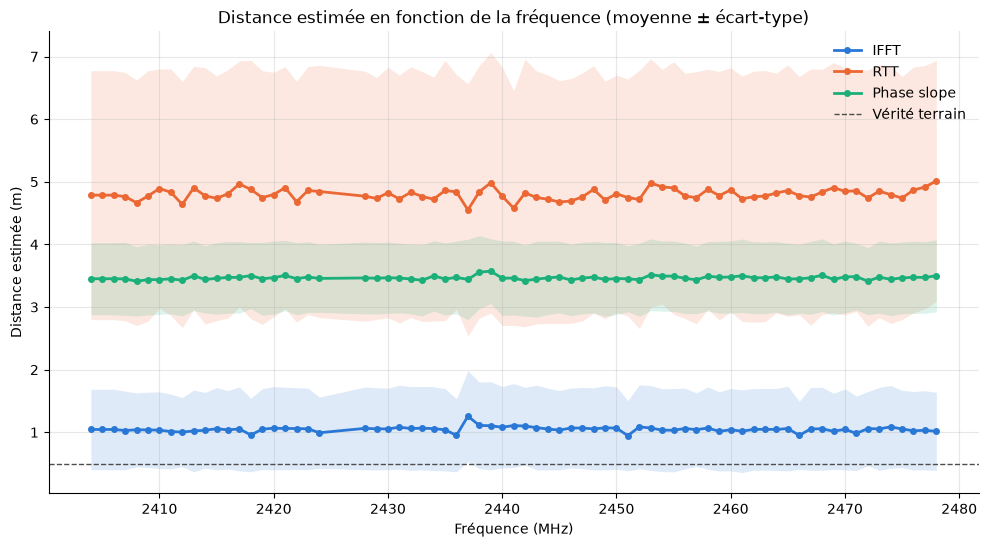

In [29]:
import matplotlib.pyplot as plt

METHODS = {
    "dist_ifft_m": ("IFFT", "#2a78d6"),
    "dist_rtt_m": ("RTT", "#eb6834"),
    "dist_phase_slope_m": ("Phase slope", "#1baf7a"),
}
stats = df.groupby("freq_mhz")[list(METHODS)].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(12, 6))
for col, (label, color) in METHODS.items():
    mean, std = stats[(col, "mean")], stats[(col, "std")]
    ax.plot(stats.index, mean, color=color, lw=2, marker="o", ms=4, label=label)
    ax.fill_between(stats.index, mean - std, mean + std, color=color, alpha=0.15, lw=0)
ax.axhline(GROUND_TRUTH_DISTANCE, color="0.3", ls="--", lw=1, label="Vérité terrain")
ax.set_xlabel("Fréquence (MHz)")
ax.set_ylabel("Distance estimée (m)")
ax.set_title("Distance estimée en fonction de la fréquence (moyenne ± écart-type)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
